In [15]:
# ===== Persiapan: folder, dataset SEED 1010 =====
import os, shutil
BASE = "/content/simuteh-2330511010"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)

from google.colab import files
up = files.upload()   # pilih buat_dataset_sintetis.py dan utils_cv.py
for n in up:
    shutil.move(n, f"{BASE}/src/{n}")

os.chdir(BASE)
!grep "SEED =" src/buat_dataset_sintetis.py
!python src/buat_dataset_sintetis.py
!ls data/sintetis/citra | wc -l
os.chdir(f"{BASE}/notebook")
print("Sekarang di:", os.getcwd())

Saving buat_dataset_sintetis.py to buat_dataset_sintetis.py
Saving utils_cv.py to utils_cv.py
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.
SEED = 1010          # 4 digit terakhir NIM 2330511010
Selesai: 60 citra tersimpan di data/sintetis
60
Sekarang di: /content/simuteh-2330511010/notebook


In [16]:
# ===== Persiapan: impor pustaka =====
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

In [17]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,           # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,           # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,      # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",    # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,         # 0 berarti tanpa penajaman
}


def _gamma_lut(g):
    """Tabel pencarian gamma: s = 255 * (r / 255) ** g (sama seperti Kode 3.2)."""
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # TODO 1: ubah ukuran agar lebar = p["lebar"], rasio aspek tetap, INTER_AREA
    h, w = img_bgr.shape[:2]
    if w != p["lebar"]:
        tinggi = int(round(h * p["lebar"] / w))
        img = cv2.resize(img_bgr, (int(p["lebar"]), tinggi), interpolation=cv2.INTER_AREA)
    else:
        img = img_bgr.copy()

    # TODO 2: koreksi gamma dengan cv2.LUT bila gamma != 1
    if p["gamma"] != 1:
        img = cv2.LUT(img, _gamma_lut(p["gamma"]))

    # TODO 3: CLAHE pada kanal V saja (HSV), lalu kembali ke BGR
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=float(p["clahe_clip"]),
                                tileGridSize=(int(p["clahe_tile"]), int(p["clahe_tile"])))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # TODO 4: redam derau sesuai penapis, kernel, sigma
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), float(p["sigma"]))
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    elif p["penapis"] != "none":
        raise ValueError(f"penapis tidak dikenal: {p['penapis']}")

    # TODO 5: unsharp masking bila tajam_k > 0
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), float(p["sigma"]))
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Overwriting ../src/praproses.py


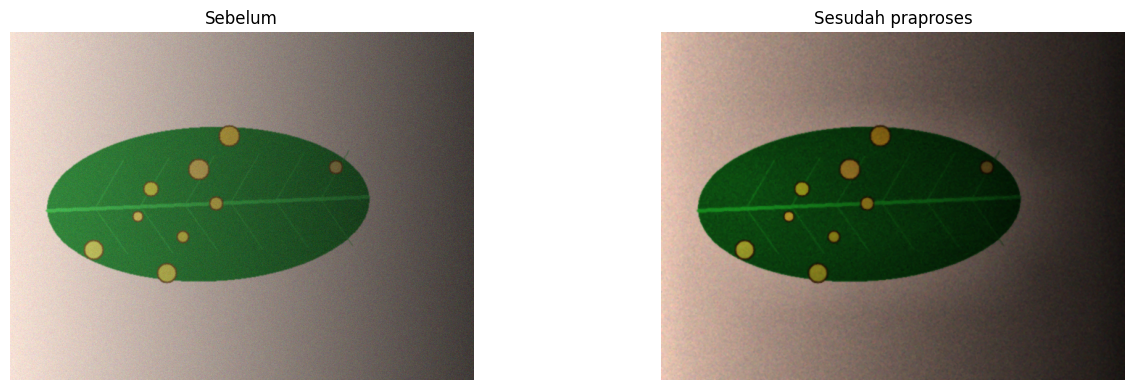

In [18]:
# ===== Langkah 5.1 | Simpan gambar uji cepat praproses() pada teh_045 =====
from praproses import praproses

img_uji = baca("../data/sintetis/citra/teh_045.png")
out_uji = praproses(img_uji, {"gamma": 1.8, "clahe_clip": 1.0, "penapis": "median", "kernel": 3})
tampil([img_uji, out_uji], ["Sebelum", "Sesudah praproses"])
plt.savefig("../hasil/b5_uji_cepat.png", dpi=120, bbox_inches="tight")

In [19]:
# ===== Langkah 5.2 | Kode 5.2: Evaluasi praproses dengan parameter CONTOH dari modul =====
from praproses import praproses, simpan_param
param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
KANAL = 2 # R, kanal terbaik dari Bagian 2 (indeks BGR: 0 = B, 1 = G, 2 = R)
label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.10        8.13
gelap                 8.96       15.61
kontras_rendah        3.69        5.00
normal                8.26        9.92
terang                6.59        6.10


In [20]:
# ===== Langkah 5.2 | Bandingkan kandidat parameter (KB kanal R, 40 citra berbercak) =====
KOND = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

def evaluasi_param(p):
    baris = []
    for _, d in label[label.kelas != "sehat"].iterrows():
        img = baca(f"../data/sintetis/citra/{d.nama_file}")
        md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        out = praproses(img, p)
        baris.append([d.kondisi_cahaya,
                      kontras_bercak(img[:, :, KANAL], md, mb),
                      kontras_bercak(out[:, :, KANAL], md, mb)])
    return pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().loc[KOND]

kandidat = {
    "A: contoh modul (gamma 1; CLAHE 2/8; median 3)": {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3},
    "B: tanpa CLAHE, median 3": {"gamma": 1.0, "clahe_clip": 0, "penapis": "median", "kernel": 3},
    "C: gamma 1.8, median 3": {"gamma": 1.8, "clahe_clip": 0, "penapis": "median", "kernel": 3},
    "D: gamma 1.8, CLAHE 1/8, median 3": {"gamma": 1.8, "clahe_clip": 1.0, "clahe_tile": 8, "penapis": "median", "kernel": 3},
    "E: gamma 1.8, CLAHE 1/8, gaussian 5": {"gamma": 1.8, "clahe_clip": 1.0, "clahe_tile": 8, "penapis": "gaussian", "kernel": 5, "sigma": 1.0},
}
ringkas = {}
for nama_k, p in kandidat.items():
    e = evaluasi_param(p)
    ringkas[nama_k] = e.KB_sesudah.round(2).tolist() + [round(e.KB_sesudah.mean(), 2)]
print(pd.DataFrame(ringkas, index=KOND + ["rata-rata"]).T.to_string())

                                                normal  gelap  terang  kontras_rendah  bayangan  rata-rata
A: contoh modul (gamma 1; CLAHE 2/8; median 3)    9.92  15.61    6.10            5.00      8.13       8.95
B: tanpa CLAHE, median 3                         13.28  15.59   10.73            7.65      6.68      10.79
C: gamma 1.8, median 3                           19.94  42.72   12.45            8.68     10.72      18.90
D: gamma 1.8, CLAHE 1/8, median 3                19.54  46.73   11.60            8.38     13.22      19.89
E: gamma 1.8, CLAHE 1/8, gaussian 5              15.15  21.10   11.26            9.35     11.36      13.64


In [21]:
# ===== Langkah 5.2 | Parameter FINAL -> param_praproses.json dan Tabel 12 =====
param = {"gamma": 1.8, "clahe_clip": 1.0, "clahe_tile": 8, "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())
tabel12 = evaluasi_param(param)
tabel12["perubahan_%"] = ((tabel12.KB_sesudah / tabel12.KB_sebelum - 1) * 100).round(1)
print(tabel12.round(2).to_string())
tabel12.round(2).to_csv("../hasil/b5_tabel12.csv")

{
  "lebar": 640,
  "gamma": 1.8,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                8.26       19.54        136.7
gelap                 8.96       46.73        421.6
terang                6.59       11.60         76.0
kontras_rendah        3.69        8.38        127.1
bayangan              5.10       13.22        159.3


In [22]:
# ===== Opsional | Cek dI (selisih rerata) sebelum dan sesudah praproses, kanal R =====
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    sehat = (md > 0) & (mb == 0)
    f = lambda c: abs(c[:, :, KANAL][mb > 0].mean() - c[:, :, KANAL][sehat].mean())
    baris.append([d.kondisi_cahaya, f(img), f(out)])
print(pd.DataFrame(baris, columns=["kondisi", "dI_sebelum", "dI_sesudah"]).groupby("kondisi").mean().round(1))

                dI_sebelum  dI_sesudah
kondisi                               
bayangan              71.2        67.6
gelap                 88.4        70.7
kontras_rendah        33.9        45.2
normal               101.2        98.9
terang                71.0        92.9


In [23]:
# ===== Langkah 5.3 | Simpangan baku kanal R pada area daun, 20 citra SEHAT (sebelum vs sesudah praproses) =====
KOND = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    out = praproses(img, param)
    a, b = img[:, :, KANAL], out[:, :, KANAL]
    baris.append([d.kondisi_cahaya, a[md > 0].std(), b[md > 0].std()])
sehat_std = pd.DataFrame(baris, columns=["kondisi", "sigma_sebelum", "sigma_sesudah"]).groupby("kondisi").mean().loc[KOND]
sehat_std["rasio"] = sehat_std.sigma_sesudah / sehat_std.sigma_sebelum
print(sehat_std.round(2).to_string())
sehat_std.round(2).to_csv("../hasil/b5_uji_bercak_palsu.csv")

                sigma_sebelum  sigma_sesudah  rasio
kondisi                                            
normal                   9.65           4.57   0.47
gelap                   10.56           1.63   0.15
terang                  11.70           8.06   0.69
kontras_rendah          10.01           5.70   0.57
bayangan                15.87           5.19   0.33


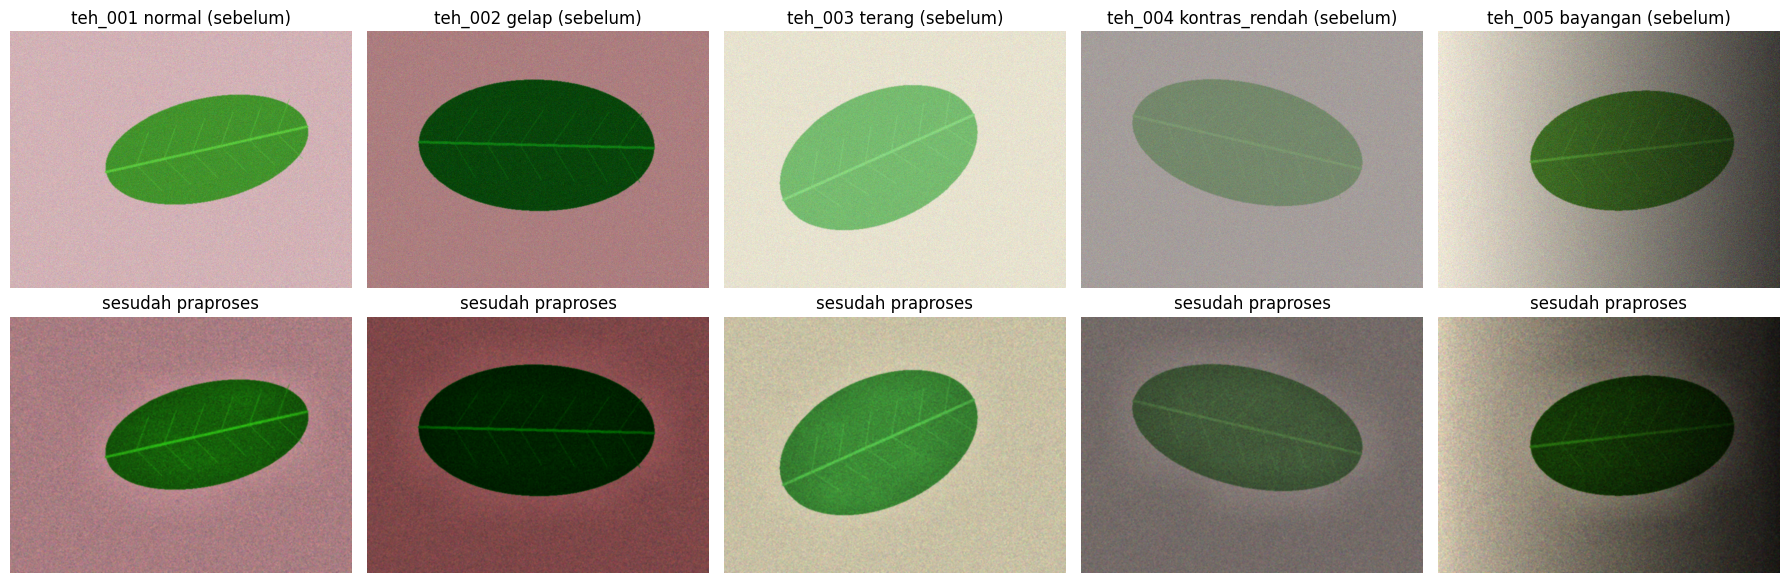

In [24]:
# ===== Langkah 5.3 | Panel sebelum-sesudah: teh_001 (normal) sampai teh_005 (bayangan), kelas sehat =====
fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, (nm, kd) in enumerate(zip(["teh_001", "teh_002", "teh_003", "teh_004", "teh_005"], KOND)):
    im = baca(f"../data/sintetis/citra/{nm}.png"); ou = praproses(im, param)
    ax[0, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"{nm} {kd} (sebelum)")
    ax[1, j].imshow(cv2.cvtColor(ou, cv2.COLOR_BGR2RGB)); ax[1, j].set_title("sesudah praproses")
for a_ in ax.ravel(): a_.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b5_panel_sehat.png", dpi=110)

In [25]:
# ===== Langkah 5.3 | Hitung gumpalan terang (z > 3) di dalam daun sehat, sebelum vs sesudah =====
def hitung_titik(kanal, md, z=3.0, luas_min=20):
    inti = cv2.erode((md > 0).astype(np.uint8), np.ones((9, 9), np.uint8)) > 0   # buang tepi daun
    k = kanal.astype(float); zz = (k - k[inti].mean()) / (k[inti].std() + 1e-6)
    n, _, st, _ = cv2.connectedComponentsWithStats(((zz > z) & inti).astype(np.uint8))
    return int(sum(st[i, cv2.CC_STAT_AREA] >= luas_min for i in range(1, n)))

baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya, hitung_titik(img[:, :, KANAL], md), hitung_titik(out[:, :, KANAL], md)])
titik = pd.DataFrame(baris, columns=["kondisi", "titik_sebelum", "titik_sesudah"])
print(titik.groupby("kondisi").mean().loc[KOND].round(2).to_string())
print("TOTAL 20 citra sehat:", titik.titik_sebelum.sum(), "->", titik.titik_sesudah.sum())

                titik_sebelum  titik_sesudah
kondisi                                     
normal                    2.0           4.00
gelap                     0.0           9.50
terang                    0.0           7.75
kontras_rendah            0.0           9.50
bayangan                  0.0           7.25
TOTAL 20 citra sehat: 8 -> 152


                abs_sebelum  abs_sesudah
kondisi                                 
normal                  0.0         0.00
gelap                   0.0         0.00
terang                  0.0         2.25
kontras_rendah          0.0         0.00
bayangan                0.0         0.00
TOTAL: {'abs_sebelum': 0.0, 'abs_sesudah': 2.25}


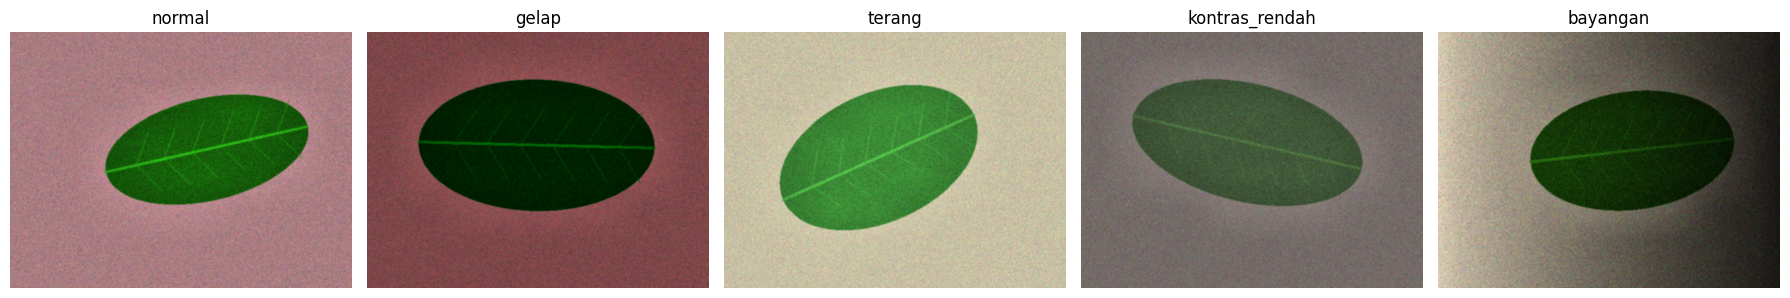

In [26]:
# ===== Langkah 5.3 | Uji ambang absolut + lokasi titik terdeteksi =====
def blob_terang(kanal, md, sd_ref, z=3.0, luas_min=20):
    inti = cv2.erode((md > 0).astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
    k = kanal.astype(float)
    zz = (k - k[inti].mean()) / (sd_ref + 1e-6)          # SD acuan = SD citra ASLI
    n, lab, st, _ = cv2.connectedComponentsWithStats(((zz > z) & inti).astype(np.uint8))
    m = np.zeros(kanal.shape, np.uint8); jml = 0
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= luas_min:
            m[lab == i] = 255; jml += 1
    return jml, m

baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    out = praproses(img, param)
    sd0 = img[:, :, KANAL][md > 0].std()
    baris.append([d.kondisi_cahaya,
                  blob_terang(img[:, :, KANAL], md, sd0)[0],
                  blob_terang(out[:, :, KANAL], md, sd0)[0]])
abs_tab = pd.DataFrame(baris, columns=["kondisi", "abs_sebelum", "abs_sesudah"])
abs_tab = abs_tab.groupby("kondisi").mean().loc[KOND].round(2)
print(abs_tab.to_string()); print("TOTAL:", abs_tab.sum().to_dict())
abs_tab.to_csv("../hasil/b5_uji_ambang_absolut.csv")

# panel lokasi titik (sesudah praproses) dengan kontur merah
fig, ax = plt.subplots(1, 5, figsize=(18, 3.5))
for j, (nm, kd) in enumerate(zip(["teh_001","teh_002","teh_003","teh_004","teh_005"], KOND)):
    im = baca(f"../data/sintetis/citra/{nm}.png")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nm}.png", 0)
    ou = praproses(im, param)
    sd0 = im[:, :, KANAL][md > 0].std()
    _, m = blob_terang(ou[:, :, KANAL], md, sd0)
    vis = ou.copy()
    cnt, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnt, -1, (0, 0, 255), 2)
    ax[j].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[j].set_title(kd); ax[j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_lokasi_titik.png", dpi=110)

teh_003.png gumpalan: 0
teh_008.png gumpalan: 0
teh_013.png gumpalan: 9


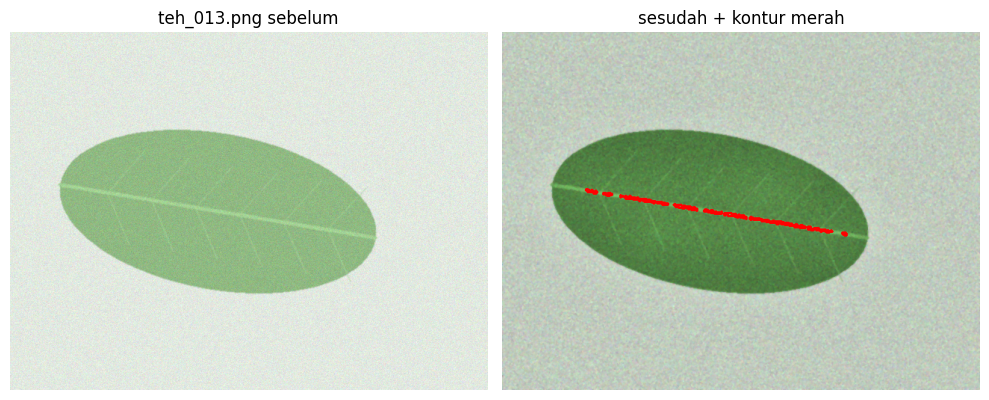

In [27]:
# ===== Langkah 5.3 | Gambar gumpalan terang pada citra sehat kondisi terang =====
for _, d in label[(label.kelas == "sehat") & (label.kondisi_cahaya == "terang")].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    ou = praproses(im, param)
    sd0 = im[:, :, KANAL][md > 0].std()
    jml, m = blob_terang(ou[:, :, KANAL], md, sd0)
    print(d.nama_file, "gumpalan:", jml)
    if jml > 0:
        vis = ou.copy()
        cnt, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, cnt, -1, (0, 0, 255), 2)
        tampil([im, vis], [f"{d.nama_file} sebelum", "sesudah + kontur merah"], ukuran=(10, 4))
        plt.savefig(f"../hasil/b5_gumpalan_{d.nama_file[:-4]}.png", dpi=110)
        break

{
  "lebar": 640,
  "gamma": 1.8,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


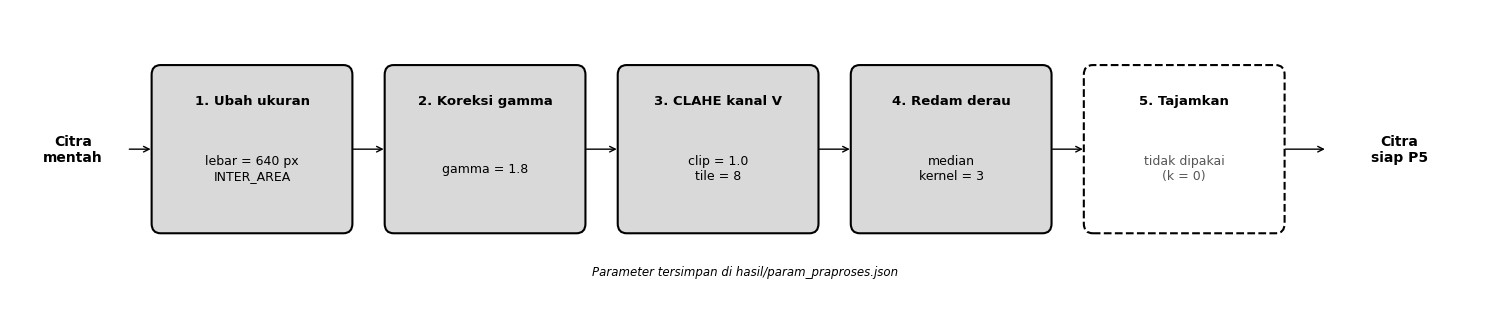


Parameter final untuk Tabel 13:
1. Ubah ukuran     | lebar = 640 px, INTER_AREA | dipakai
2. Koreksi gamma   | gamma = 1.8 | dipakai
3. CLAHE kanal V   | clip = 1.0, tile = 8 | dipakai
4. Redam derau     | median, kernel = 3 | dipakai
5. Tajamkan        | tidak dipakai, (k = 0) | tidak dipakai


In [28]:
# Kode 5.4 Diagram rangkaian praproses final dan parameter untuk Tabel 13
import json
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Memastikan folder hasil ada dan membaca/membuat parameter default
os.makedirs("../hasil", exist_ok=True)
path_param = "../hasil/param_praproses.json"

try:
    with open(path_param) as f:
        p = json.load(f)
except FileNotFoundError:
    # Parameter default jika file belum sempat dibuat di sel sebelumnya
    p = {
        "lebar": 640,
        "gamma": 1.8,
        "clahe_clip": 1.0,
        "clahe_tile": 8,
        "penapis": "median",
        "kernel": 3,
        "sigma": 1.0,
        "tajam_k": 0.0
    }
    with open(path_param, "w") as f:
        json.dump(p, f, indent=2)

print(json.dumps(p, indent=2))

# teks isi tiap kotak berdasarkan parameter final
isi_ukuran = f"lebar = {p['lebar']} px\nINTER_AREA"
isi_gamma = (f"gamma = {p['gamma']}" if p["gamma"] != 1
             else "tidak dipakai\n(gamma = 1)")
isi_clahe = (f"clip = {p['clahe_clip']}\ntile = {p['clahe_tile']}"
             if p["clahe_clip"] > 0 else "tidak dipakai\n(clip = 0)")
if p["penapis"] == "none":
    isi_redam = "tidak dipakai"
elif p["penapis"] == "gaussian":
    isi_redam = f"gaussian\nkernel = {p['kernel']}, sigma = {p['sigma']}"
else:
    isi_redam = f"{p['penapis']}\nkernel = {p['kernel']}"
isi_tajam = (f"unsharp\nk = {p['tajam_k']}" if p["tajam_k"] > 0
             else "tidak dipakai\n(k = 0)")

langkah = [
    ("1. Ubah ukuran", isi_ukuran, True),
    ("2. Koreksi gamma", isi_gamma, p["gamma"] != 1),
    ("3. CLAHE kanal V", isi_clahe, p["clahe_clip"] > 0),
    ("4. Redam derau", isi_redam, p["penapis"] != "none"),
    ("5. Tajamkan", isi_tajam, p["tajam_k"] > 0),
]

fig, ax = plt.subplots(figsize=(15, 3.2))
ax.set_xlim(0, 16.4); ax.set_ylim(0, 3); ax.axis("off")
y0, tinggi, lebar_k, jarak = 0.7, 1.7, 2.2, 2.6

ax.text(0.7, y0 + tinggi / 2, "Citra\nmentah", ha="center", va="center",
        fontsize=10, fontweight="bold")
ax.annotate("", xy=(1.6, y0 + tinggi / 2), xytext=(1.3, y0 + tinggi / 2),
            arrowprops=dict(arrowstyle="->", color="black"))

for i, (judul, isi, aktif) in enumerate(langkah):
    xl = 1.6 + i * jarak
    kotak = FancyBboxPatch((xl, y0), lebar_k, tinggi,
                           boxstyle="round,pad=0.02,rounding_size=0.1",
                           facecolor="#d9d9d9" if aktif else "white",
                           edgecolor="black", linewidth=1.5,
                           linestyle="-" if aktif else "--")
    ax.add_patch(kotak)
    ax.text(xl + lebar_k / 2, y0 + tinggi - 0.35, judul, ha="center",
            va="center", fontsize=9.5, fontweight="bold")
    ax.text(xl + lebar_k / 2, y0 + 0.65, isi, ha="center", va="center",
            fontsize=9, color="black" if aktif else "#555555")
    if i < len(langkah) - 1:
        ax.annotate("", xy=(xl + jarak, y0 + tinggi / 2),
                    xytext=(xl + lebar_k, y0 + tinggi / 2),
                    arrowprops=dict(arrowstyle="->", color="black"))

x_akhir = 1.6 + (len(langkah) - 1) * jarak + lebar_k
ax.annotate("", xy=(x_akhir + 0.5, y0 + tinggi / 2),
            xytext=(x_akhir, y0 + tinggi / 2),
            arrowprops=dict(arrowstyle="->", color="black"))
ax.text(x_akhir + 1.3, y0 + tinggi / 2, "Citra\nsiap P5", ha="center",
        va="center", fontsize=10, fontweight="bold")
ax.text(8.2, 0.25, "Parameter tersimpan di hasil/param_praproses.json",
        ha="center", fontsize=8.5, style="italic")
plt.tight_layout()
plt.savefig("../hasil/b5_pipeline_final.png", dpi=150)
plt.show()

# parameter final untuk disalin ke kolom "Parameter final" Tabel 13
print("\nParameter final untuk Tabel 13:")
for judul, isi, aktif in langkah:
    print(f"{judul:18s} | {isi.replace(chr(10), ', ')}"
          f" | {'dipakai' if aktif else 'tidak dipakai'}")